In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!pip install -q librosa soundfile tqdm

In [ ]:
import os
import librosa
import soundfile as sf
from tqdm import tqdm

In [ ]:
REAL_INPUT = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Real/clips"
FAKE_INPUT = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Fake"

REAL_OUTPUT = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Processed/Real"
FAKE_OUTPUT = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Processed/Fake"

os.makedirs(REAL_OUTPUT, exist_ok=True)
os.makedirs(FAKE_OUTPUT, exist_ok=True)

In [ ]:
import pandas as pd

validated_file = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Real/validated.tsv"

df = pd.read_csv(validated_file, sep="\t")

print("Validated recordings:", len(df))

Validated recordings: 11131


In [ ]:
print("Real exists :", os.path.exists(REAL_INPUT))
print("Fake exists :", os.path.exists(FAKE_INPUT))

print("Real files :", len(os.listdir(REAL_INPUT)))
print("Fake files :", len(os.listdir(FAKE_INPUT)))

Real exists : True
Fake exists : True
Real files : 19029
Fake files : 11131


In [ ]:
import pandas as pd

validated_file = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Real/validated.tsv"

df = pd.read_csv(validated_file, sep="\t")

print("Validated recordings:", len(df))

Validated recordings: 11131


In [ ]:
real_files = df["path"].tolist()

print("Real files to process:", len(real_files))
print(real_files[:5])

Real files to process: 11131
['common_voice_hi_32761781.mp3', 'common_voice_hi_28951344.mp3', 'common_voice_hi_38247205.mp3', 'common_voice_hi_27972227.mp3', 'common_voice_hi_37868078.mp3']


In [ ]:
#Define the preprocessing function
TARGET_SR = 16000
TARGET_DURATION = 3
TARGET_LENGTH = TARGET_SR * TARGET_DURATION

def preprocess_audio(input_path, output_path):
    try:
        # Load audio and convert to mono at 16 kHz
        audio, sr = librosa.load(
            input_path,
            sr=TARGET_SR,
            mono=True
        )

        # Trim or pad to exactly 3 seconds
        if len(audio) > TARGET_LENGTH:
            audio = audio[:TARGET_LENGTH]
        else:
            audio = librosa.util.fix_length(audio, size=TARGET_LENGTH)

        # Save as WAV
        sf.write(output_path, audio, TARGET_SR)

    except Exception as e:
        print(f"Error processing {input_path}")
        print(e)

In [ ]:
#Process the validated REAL files
from tqdm import tqdm

for file in tqdm(real_files):
    preprocess_audio(
        os.path.join(REAL_INPUT, file),
        os.path.join(
            REAL_OUTPUT,
            file.replace(".mp3", ".wav")
        )
    )

100%|██████████| 11131/11131 [2:03:42<00:00,  1.50it/s]


In [ ]:
print("Processed Real:", len(os.listdir(REAL_OUTPUT)))

Processed Real: 11131


In [ ]:
fake_files = [f for f in os.listdir(FAKE_INPUT) if f.endswith(".mp3")]

print("Fake files to process:", len(fake_files))
print(fake_files[:5])

Fake files to process: 11131
['common_voice_hi_26202790.mp3', 'common_voice_hi_26202789.mp3', 'common_voice_hi_26202788.mp3', 'common_voice_hi_26202787.mp3', 'common_voice_hi_26202786.mp3']


In [ ]:
#Process Fake Audio
from tqdm import tqdm

for file in tqdm(fake_files):
    preprocess_audio(
        os.path.join(FAKE_INPUT, file),
        os.path.join(
            FAKE_OUTPUT,
            file.replace(".mp3", ".wav")
        )
    )

100%|██████████| 11131/11131 [2:43:57<00:00,  1.13it/s]


In [ ]:
print("Processed Real :", len(os.listdir(REAL_OUTPUT)))
print("Processed Fake :", len(os.listdir(FAKE_OUTPUT)))

Processed Real : 11131
Processed Fake : 11131


In [ ]:
#Hindi MUSAN Noise Augmentation

In [ ]:
import os
import random
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
from tqdm import tqdm

In [ ]:
#Set paths

# MUSAN Noise Folder (same as Phase 4)
NOISE_DIR = "/content/drive/MyDrive/VocaTrust/Phase4_Noise_Robustness/noise_samples"

# Hindi processed dataset
REAL_DIR = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Processed/Real"
FAKE_DIR = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Processed/Fake"

# Output folders
OUTPUT_REAL = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Augmented/Real"
OUTPUT_FAKE = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Augmented/Fake"

# Logs
LOG_DIR = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Augmentation_Logs"

os.makedirs(OUTPUT_REAL, exist_ok=True)
os.makedirs(OUTPUT_FAKE, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

In [ ]:
#read noise files
noise_files = []

for root, _, files in os.walk(NOISE_DIR):
    for file in files:
        if file.endswith(".wav"):
            noise_files.append(os.path.join(root, file))

random.shuffle(noise_files)

print("Total Noise Files:", len(noise_files))

Total Noise Files: 930


In [ ]:
#SNR Function


def add_noise_snr(clean, noise, snr_db):

    clean_power = np.mean(clean ** 2)
    noise_power = np.mean(noise ** 2)

    desired_noise_power = clean_power / (10 ** (snr_db / 10))

    noise = noise * np.sqrt(desired_noise_power / noise_power)

    noisy = clean + noise

    max_amp = np.max(np.abs(noisy))

    if max_amp > 1:
        noisy = noisy / max_amp

    return noisy

In [ ]:
#Augment Real Audio


snr_values = [5, 10, 15, 20]

log = []

noise_index = 0

real_files = sorted([
    f for f in os.listdir(REAL_DIR)
    if f.endswith(".wav")
])

for file in tqdm(real_files):

    input_path = os.path.join(REAL_DIR, file)
    output_path = os.path.join(OUTPUT_REAL, file)

    if os.path.exists(output_path):
        continue

    clean, sr = librosa.load(input_path, sr=16000)

    noise_path = noise_files[noise_index]

    noise_index += 1

    if noise_index >= len(noise_files):
        random.shuffle(noise_files)
        noise_index = 0

    noise, _ = librosa.load(noise_path, sr=16000)

    if len(noise) < len(clean):
        repeats = int(np.ceil(len(clean) / len(noise)))
        noise = np.tile(noise, repeats)

    noise = noise[:len(clean)]

    snr = random.choice(snr_values)

    noisy = add_noise_snr(clean, noise, snr)

    sf.write(output_path, noisy, sr)

    log.append({
        "Original File": file,
        "Noise File": os.path.basename(noise_path),
        "SNR": snr,
        "Output File": file
    })

pd.DataFrame(log).to_csv(
    os.path.join(LOG_DIR, "real_augmentation_log.csv"),
    index=False
)

print("✅ Hindi Real augmentation completed!")

100%|██████████| 11131/11131 [55:10<00:00,  3.36it/s]


✅ Hindi Real augmentation completed!


In [ ]:
print("Augmented Real:", len(os.listdir(OUTPUT_REAL)))

Augmented Real: 11131


In [ ]:
#Agument fake audio

import os
import random
import numpy as np
import pandas as pd
import librosa
import soundfile as sf
from tqdm import tqdm

# ===========================
# Paths
# ===========================

FAKE_DIR = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Processed/Fake"

OUTPUT_FAKE = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Augmented/Fake"

LOG_DIR = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Augmentation_Logs"

NOISE_DIR = "/content/drive/MyDrive/VocaTrust/Phase4_Noise_Robustness/noise_samples"

os.makedirs(OUTPUT_FAKE, exist_ok=True)
os.makedirs(LOG_DIR, exist_ok=True)

# ===========================
# Read Noise Files
# ===========================

noise_files = []

for root, _, files in os.walk(NOISE_DIR):
    for file in files:
        if file.endswith(".wav"):
            noise_files.append(os.path.join(root, file))

random.shuffle(noise_files)

print("Total Noise Files:", len(noise_files))

# ===========================
# SNR Function
# ===========================

def add_noise_snr(clean, noise, snr_db):

    clean_power = np.mean(clean ** 2)
    noise_power = np.mean(noise ** 2)

    desired_noise_power = clean_power / (10 ** (snr_db / 10))

    noise = noise * np.sqrt(desired_noise_power / noise_power)

    noisy = clean + noise

    max_amp = np.max(np.abs(noisy))

    if max_amp > 1:
        noisy = noisy / max_amp

    return noisy

# ===========================
# Augment Fake Dataset
# ===========================

snr_values = [5, 10, 15, 20]

log = []

noise_index = 0

fake_files = sorted([
    f for f in os.listdir(FAKE_DIR)
    if f.endswith(".wav")
])

print("Total Fake Files:", len(fake_files))

for file in tqdm(fake_files):

    input_path = os.path.join(FAKE_DIR, file)
    output_path = os.path.join(OUTPUT_FAKE, file)

    # Skip already processed files
    if os.path.exists(output_path):
        continue

    # Load clean speech
    clean, sr = librosa.load(input_path, sr=16000)

    # Select a noise file
    noise_path = noise_files[noise_index]

    noise_index += 1

    # Reshuffle when all noise files are used
    if noise_index >= len(noise_files):
        random.shuffle(noise_files)
        noise_index = 0

    # Load noise
    noise, _ = librosa.load(noise_path, sr=16000)

    # Match noise length to speech length
    if len(noise) < len(clean):
        repeats = int(np.ceil(len(clean) / len(noise)))
        noise = np.tile(noise, repeats)

    noise = noise[:len(clean)]

    # Random SNR
    snr = random.choice(snr_values)

    # Add noise
    noisy = add_noise_snr(clean, noise, snr)

    # Save augmented audio
    sf.write(output_path, noisy, sr)

    # Log details
    log.append({
        "Original File": file,
        "Noise File": os.path.basename(noise_path),
        "SNR": snr,
        "Output File": file
    })

# ===========================
# Save Log
# ===========================

log_df = pd.DataFrame(log)

log_df.to_csv(
    os.path.join(LOG_DIR, "fake_augmentation_log.csv"),
    index=False
)

print("✅ Hindi Fake augmentation completed successfully!")

# ===========================
# Verify
# ===========================

print("\nVerification")
print("Augmented Fake Files:",
      len([f for f in os.listdir(OUTPUT_FAKE) if f.endswith(".wav")]))

print("Log Records:",
      len(pd.read_csv(os.path.join(LOG_DIR, "fake_augmentation_log.csv"))))

Total Noise Files: 930
Total Fake Files: 11131


100%|██████████| 11131/11131 [00:21<00:00, 519.79it/s] 


✅ Hindi Fake augmentation completed successfully!

Verification
Augmented Fake Files: 11131


EmptyDataError: No columns to parse from file

In [ ]:
print("Augmented Real:", len(os.listdir(OUTPUT_FAKE)))

Augmented Real: 11131


In [ ]:
#Feature Extraction (Hindi Noisy Dataset)

In [ ]:
import os
import librosa
import numpy as np
from tqdm.auto import tqdm

In [ ]:
#Dataset Paths
# Hindi augmented dataset

real_path = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Augmented/Real"
fake_path = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Hindi/Augmented/Fake"

# Save directory

save_dir = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Features/Hindi"

os.makedirs(save_dir, exist_ok=True)

print("Real Files :", len(os.listdir(real_path)))
print("Fake Files :", len(os.listdir(fake_path)))

Real Files : 11131
Fake Files : 11131


In [ ]:
#Feature Extraction Function
def extract_features(file_path):

    try:

        y, sr = librosa.load(file_path, sr=16000)

        if len(y) < 2048:
            return None

        mfcc = librosa.feature.mfcc(
            y=y,
            sr=sr,
            n_mfcc=13,
            n_fft=1024,
            hop_length=512
        )

        delta = librosa.feature.delta(mfcc)

        delta2 = librosa.feature.delta(
            mfcc,
            order=2
        )

        features = np.vstack((mfcc, delta, delta2))

        max_len = 100

        if features.shape[1] < max_len:

            features = np.pad(
                features,
                ((0,0),(0,max_len-features.shape[1])),
                mode="constant"
            )

        else:

            features = features[:, :100]

        return features.astype(np.float32)

    except Exception:
        return None

In [ ]:
#Test One File
sample_file = os.path.join(
    real_path,
    os.listdir(real_path)[0]
)

sample = extract_features(sample_file)

print(sample.shape)

(39, 100)


In [ ]:
#Extract Features

X_hindi = []
y_hindi = []

# ============================================
# REAL AUDIO
# ============================================

print("Processing Hindi REAL audio...")

real_files = sorted([
    os.path.join(real_path, f)
    for f in os.listdir(real_path)
    if f.endswith(".wav")
])

with tqdm(
    total=len(real_files),
    desc="REAL",
    unit="file",
    colour="green"
) as pbar:

    for file in real_files:

        feature = extract_features(file)

        if feature is not None:
            X_hindi.append(feature)
            y_hindi.append(1)

        pbar.update(1)

        if pbar.n % 500 == 0:
            pbar.set_postfix(
                Processed=f"{pbar.n}/{len(real_files)}"
            )

# ============================================
# FAKE AUDIO
# ============================================

print("\nProcessing Hindi FAKE audio...")

fake_files = sorted([
    os.path.join(fake_path, f)
    for f in os.listdir(fake_path)
    if f.endswith(".wav")
])

with tqdm(
    total=len(fake_files),
    desc="FAKE",
    unit="file",
    colour="blue"
) as pbar:

    for file in fake_files:

        feature = extract_features(file)

        if feature is not None:
            X_hindi.append(feature)
            y_hindi.append(0)

        pbar.update(1)

        if pbar.n % 500 == 0:
            pbar.set_postfix(
                Processed=f"{pbar.n}/{len(fake_files)}"
            )

print("\n✅ Feature Extraction Completed!")

Processing Hindi REAL audio...


REAL:   0%|          | 0/11131 [00:00<?, ?file/s]


Processing Hindi FAKE audio...


FAKE:   0%|          | 0/11131 [00:00<?, ?file/s]


✅ Feature Extraction Completed!


In [ ]:
#Convert to NumPy
X_hindi = np.array(X_hindi, dtype=np.float32)
y_hindi = np.array(y_hindi)

print("X_hindi shape :", X_hindi.shape)
print("y_hindi shape :", y_hindi.shape)

X_hindi shape : (22262, 39, 100)
y_hindi shape : (22262,)


In [ ]:
#Save
np.save(
    os.path.join(save_dir, "X_hindi.npy"),
    X_hindi
)

np.save(
    os.path.join(save_dir, "y_hindi.npy"),
    y_hindi
)

print("✅ Hindi Features Saved Successfully!")

print(os.listdir(save_dir))

✅ Hindi Features Saved Successfully!
['X_hindi.npy', 'y_hindi.npy']


In [ ]:

y_hindi.shape
# (22262,)

(22262,)

In [ ]:
X_hindi.shape

(22262, 39, 100)

In [ ]:
#merge the english and hindi

In [ ]:
#Load English and Hindi Features

import os
import numpy as np

# ===========================
# English Dataset
# ===========================

X_english = np.load(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/English/X_combined.npy"
)

y_english = np.load(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/English/y_combined.npy"
)

# ===========================
# Hindi Dataset
# ===========================

X_hindi = np.load(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Features/Hindi/X_hindi.npy"
)

y_hindi = np.load(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Features/Hindi/y_hindi.npy"
)

print("English X :", X_english.shape)
print("English y :", y_english.shape)

print("Hindi X   :", X_hindi.shape)
print("Hindi y   :", y_hindi.shape)

English X : (91198, 39, 100)
English y : (91198,)
Hindi X   : (22262, 39, 100)
Hindi y   : (22262,)


In [ ]:
#Combine
# ===========================
# Combine English + Hindi
# ===========================

X_multilingual = np.concatenate(
    (X_english, X_hindi),
    axis=0
)

y_multilingual = np.concatenate(
    (y_english, y_hindi),
    axis=0
)

print("✅ Combined Successfully\n")

print("X_multilingual :", X_multilingual.shape)
print("y_multilingual :", y_multilingual.shape)

✅ Combined Successfully

X_multilingual : (113460, 39, 100)
y_multilingual : (113460,)


In [ ]:
#Save

save_dir = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Combined"

os.makedirs(save_dir, exist_ok=True)

np.save(
    os.path.join(save_dir, "X_multilingual.npy"),
    X_multilingual
)

np.save(
    os.path.join(save_dir, "y_multilingual.npy"),
    y_multilingual
)

print("✅ Multilingual dataset saved successfully!")

✅ Multilingual dataset saved successfully!


In [ ]:
#Verify

X = np.load(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Combined/X_multilingual.npy"
)

y = np.load(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Combined/y_multilingual.npy"
)

print("X :", X.shape)
print("y :", y.shape)

X : (113460, 39, 100)
y : (113460,)


In [ ]:
#Train/Test Split


In [ ]:
#Load Multilingual Dataset
import numpy as np

X = np.load(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Combined/X_multilingual.npy"
)

y = np.load(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Combined/y_multilingual.npy"
)

print("X :", X.shape)
print("y :", y.shape)

X : (113460, 39, 100)
y : (113460,)


In [ ]:
#Add CNN Channel
X = X[..., np.newaxis]

print("New X shape :", X.shape)

New X shape : (113460, 39, 100, 1)


In [ ]:
#train-test-split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
    shuffle=True
)

print("Training set :", X_train.shape)
print("Testing set  :", X_test.shape)

Training set : (90768, 39, 100, 1)
Testing set  : (22692, 39, 100, 1)


In [ ]:
#Verify Label Distribution

import numpy as np

print("Training Labels")

unique, counts = np.unique(y_train, return_counts=True)

for label, count in zip(unique, counts):
    print(label, ":", count)

print("\nTesting Labels")

unique, counts = np.unique(y_test, return_counts=True)

for label, count in zip(unique, counts):
    print(label, ":", count)

Training Labels
0 : 49513
1 : 41255

Testing Labels
0 : 12378
1 : 10314


In [ ]:
#save the train test split
import os

split_dir = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Combined/Train_Test_Split"

os.makedirs(split_dir, exist_ok=True)

np.save(os.path.join(split_dir, "X_train.npy"), X_train)
np.save(os.path.join(split_dir, "X_test.npy"), X_test)
np.save(os.path.join(split_dir, "y_train.npy"), y_train)
np.save(os.path.join(split_dir, "y_test.npy"), y_test)

print("✅ Train/Test split saved successfully!")

✅ Train/Test split saved successfully!


In [ ]:
#model training

In [ ]:
#Import Libraries
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.regularizers import l2

In [ ]:
#Build the Enhanced CNN
improved_model = Sequential([

    # ===========================
    # Block 1
    # ===========================

    Conv2D(
        filters=32,
        kernel_size=(3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=l2(0.001),
        input_shape=(39,100,1)
    ),

    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.25),

    # ===========================
    # Block 2
    # ===========================

    Conv2D(
        filters=64,
        kernel_size=(3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=l2(0.001)
    ),

    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.30),

    # ===========================
    # Block 3
    # ===========================

    Conv2D(
        filters=128,
        kernel_size=(3,3),
        activation='relu',
        padding='same',
        kernel_regularizer=l2(0.001)
    ),

    BatchNormalization(),
    MaxPooling2D((2,2)),
    Dropout(0.40),

    # ===========================

    Flatten(),

    Dense(
        128,
        activation='relu',
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.50),

    Dense(
        1,
        activation='sigmoid'
    )

])

print("✅ Enhanced CNN Created Successfully")

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


✅ Enhanced CNN Created Successfully


In [ ]:
#Compile the Model
from tensorflow.keras.optimizers import Adam

improved_model.compile(

    optimizer=Adam(
        learning_rate=0.0001
    ),

    loss="binary_crossentropy",

    metrics=["accuracy"]

)

print("✅ Model Compiled Successfully")

✅ Model Compiled Successfully


In [ ]:
#Model Summary
improved_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 39, 100, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 39, 100, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 19, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 19, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 19, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 19, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 9, 25, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 9, 25, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 9, 25, 128)     │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 9, 25, 128)     │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 12, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 12, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6144)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       786,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 880,257 (3.36 MB)

 Trainable params: 879,809 (3.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
#define model path
import os

model_dir = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Models"

In [ ]:
#Callbacks
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

checkpoint_path = os.path.join(
    model_dir,
    "Best_Multilingual_Model.keras"
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

print("✅ Callbacks Created Successfully")

✅ Callbacks Created Successfully


In [ ]:
#Train the Model
history = improved_model.fit(

    X_train,
    y_train,

    validation_data=(X_test, y_test),

    epochs=50,

    batch_size=32,

    callbacks=[
        early_stop,
        checkpoint
    ],

    verbose=1

)

Epoch 1/50
2837/2837 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.7346 - loss: 0.8938
Epoch 1: val_accuracy improved from None to 0.79442, saving model to /content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Models/Best_Multilingual_Model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Models/Best_Multilingual_Model.keras
2837/2837 ━━━━━━━━━━━━━━━━━━━━ 43s 11ms/step - accuracy: 0.8184 - loss: 0.7111 - val_accuracy: 0.7944 - val_loss: 0.7139
Epoch 2/50
2832/2837 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9101 - loss: 0.4647
Epoch 2: val_accuracy improved from 0.79442 to 0.91398, saving model to /content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Models/Best_Multilingual_Model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Models/Best_Multilingual_Model.keras
2837/2837 ━━━━━━━━━━━━━━━━━━━━ 23s 8ms/step - accuracy: 0.9174 - loss: 0.4271 - val_accuracy: 0.9140 - val_loss: 0.3928
Epoch 3/50
2

In [ ]:
#load the best model
from tensorflow.keras.models import load_model

improved_model = load_model(
    os.path.join(
        model_dir,
        "Best_Multilingual_Model.keras"
    )
)

print("✅ Best Model Loaded Successfully")

✅ Best Model Loaded Successfully


In [ ]:
#save the final model
improved_model.save(
    os.path.join(
        model_dir,
        "VocaTrust_Multilingual_Final.keras"
    )
)

print("✅ Final Model Saved Successfully")

✅ Final Model Saved Successfully


In [ ]:
#Save Training History
import pandas as pd

history_df = pd.DataFrame(history.history)

history_df.to_csv(
    os.path.join(
        model_dir,
        "training_history.csv"
    ),
    index=False
)

print("✅ Training History Saved Successfully")

✅ Training History Saved Successfully


In [ ]:
#Load Best Model
from tensorflow.keras.models import load_model
import os

model_dir = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Models"

improved_model = load_model(
    os.path.join(
        model_dir,
        "Best_Multilingual_Model.keras"
    )
)

print("✅ Best multilingual model loaded successfully!")

✅ Best multilingual model loaded successfully!


In [ ]:
#Evaluate the Model
test_loss, test_accuracy = improved_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"\nTest Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")

710/710 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9916 - loss: 0.0781

Test Loss     : 0.0781
Test Accuracy : 0.9916


In [ ]:
#Predictions
import numpy as np

y_pred_prob = improved_model.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int)

print("Prediction shape:", y_pred.shape)

710/710 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step
Prediction shape: (22692, 1)


In [ ]:
#Performance Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_prob)

print("="*45)
print("MULTILINGUAL MODEL PERFORMANCE")
print("="*45)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")
print(f"ROC AUC  : {roc_auc:.4f}")

MULTILINGUAL MODEL PERFORMANCE
Accuracy : 0.9916
Precision: 0.9913
Recall   : 0.9902
F1 Score : 0.9907
ROC AUC  : 0.9996


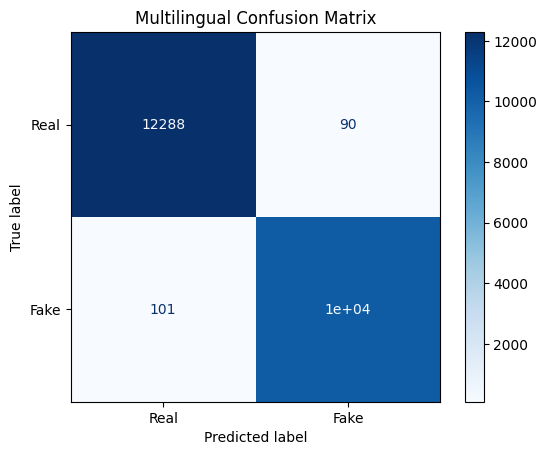

In [ ]:
#confusion Matrix
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real", "Fake"]
)

disp.plot(cmap="Blues")

plt.title("Multilingual Confusion Matrix")
plt.show()

In [ ]:
#Classification Report
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Real","Fake"]
    )
)

              precision    recall  f1-score   support

        Real       0.99      0.99      0.99     12378
        Fake       0.99      0.99      0.99     10314

    accuracy                           0.99     22692
   macro avg       0.99      0.99      0.99     22692
weighted avg       0.99      0.99      0.99     22692



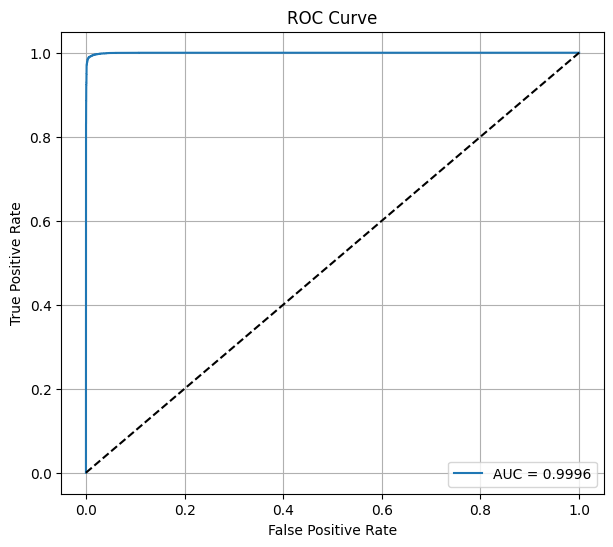

In [ ]:
#ROC Curve
from sklearn.metrics import roc_curve

fpr, tpr, _ = roc_curve(y_test, y_pred_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

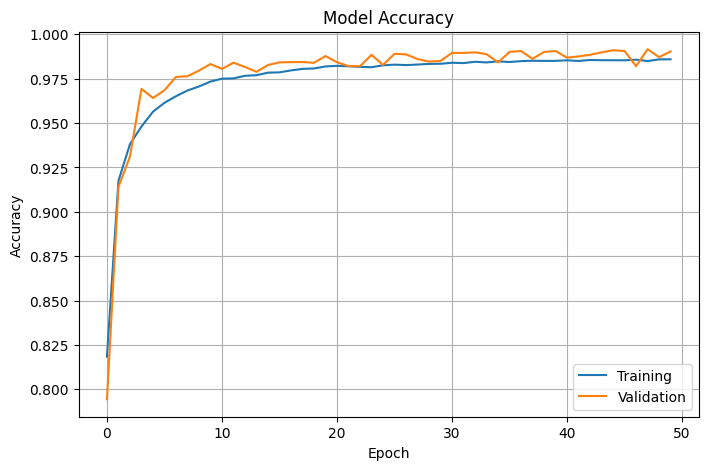

In [ ]:
#Accuracy Curve
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training")

plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("Model Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

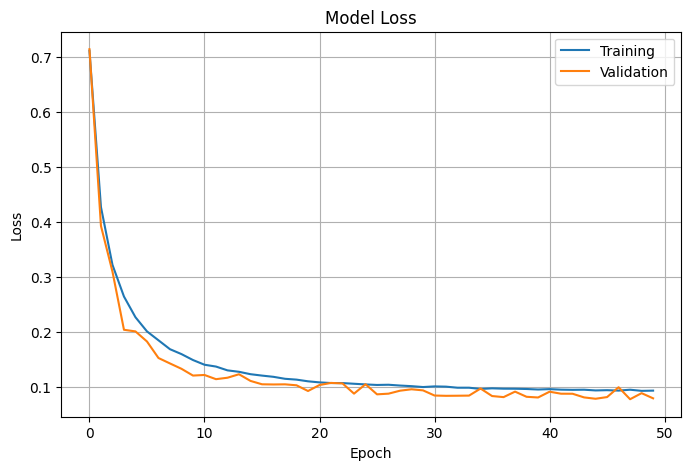

In [ ]:
#Loss Curve
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training")

plt.plot(history.history["val_loss"], label="Validation")

plt.title("Model Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

710/710 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9916 - loss: 0.0781
710/710 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
✅ Evaluation metrics saved
✅ Classification report saved


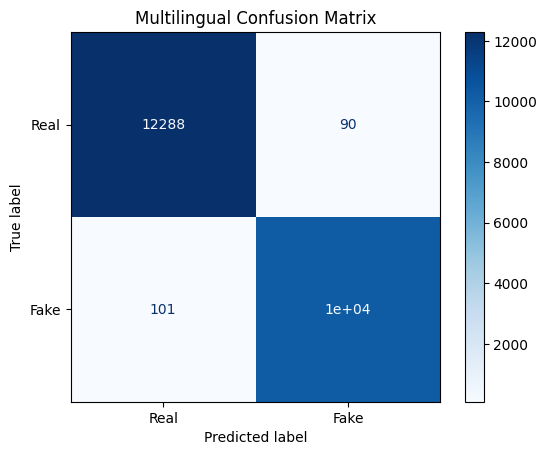

✅ Confusion matrix saved


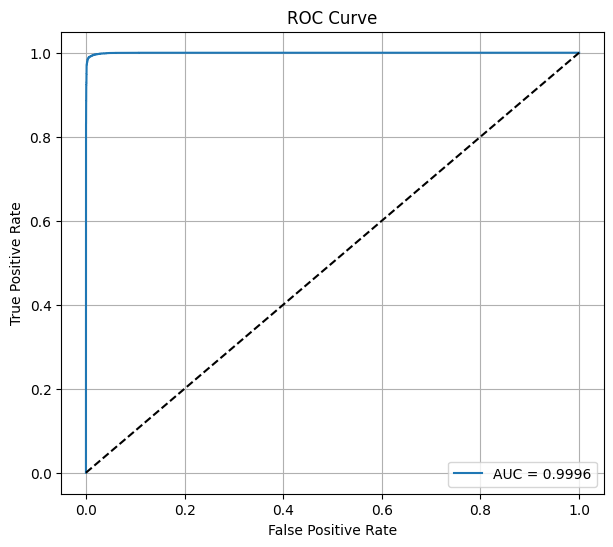

✅ ROC curve saved


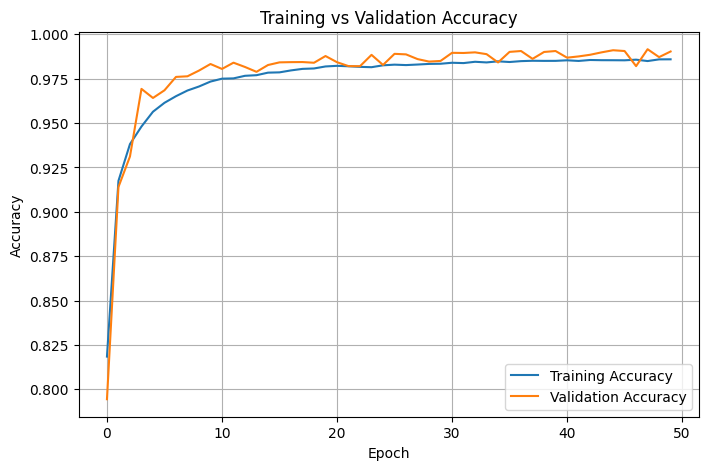

✅ Accuracy graph saved


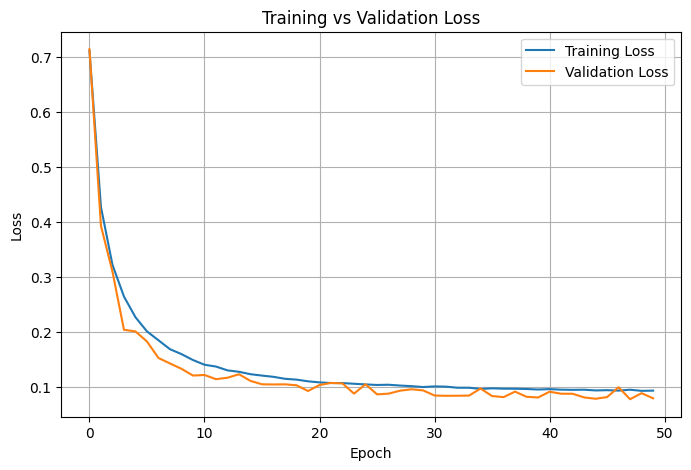

✅ Loss graph saved

FINAL MULTILINGUAL MODEL PERFORMANCE
Test Loss      : 0.0781
Test Accuracy  : 0.9916
Accuracy       : 0.9916
Precision      : 0.9913
Recall         : 0.9902
F1 Score       : 0.9907
ROC AUC Score  : 0.9996

✅ Everything has been saved successfully!


In [ ]:
#save
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    roc_curve
)

# ==========================================================
# Create Evaluation Folder
# ==========================================================

evaluation_dir = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Evaluation"

os.makedirs(evaluation_dir, exist_ok=True)

# ==========================================================
# Evaluate Model
# ==========================================================

test_loss, test_accuracy = improved_model.evaluate(
    X_test,
    y_test,
    verbose=1
)

# ==========================================================
# Predictions
# ==========================================================

y_pred_prob = improved_model.predict(X_test)

y_pred = (y_pred_prob > 0.5).astype(int)

# ==========================================================
# Performance Metrics
# ==========================================================

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_prob)

results = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Test Accuracy",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],
    "Value": [
        test_loss,
        test_accuracy,
        accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

results.to_csv(
    os.path.join(evaluation_dir, "evaluation_metrics.csv"),
    index=False
)

print("✅ Evaluation metrics saved")

# ==========================================================
# Classification Report
# ==========================================================

report = classification_report(
    y_test,
    y_pred,
    target_names=["Real","Fake"]
)

with open(
    os.path.join(evaluation_dir,"classification_report.txt"),
    "w"
) as f:
    f.write(report)

print("✅ Classification report saved")

# ==========================================================
# Confusion Matrix
# ==========================================================

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Real","Fake"]
)

disp.plot(cmap="Blues")

plt.title("Multilingual Confusion Matrix")

plt.savefig(
    os.path.join(evaluation_dir,"confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Confusion matrix saved")

# ==========================================================
# ROC Curve
# ==========================================================

fpr, tpr, _ = roc_curve(y_test, y_pred_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {roc_auc:.4f}"
)

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(evaluation_dir,"roc_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ ROC curve saved")

# ==========================================================
# Accuracy Graph
# ==========================================================

plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"],label="Training Accuracy")
plt.plot(history.history["val_accuracy"],label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")

plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(evaluation_dir,"accuracy_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Accuracy graph saved")

# ==========================================================
# Loss Graph
# ==========================================================

plt.figure(figsize=(8,5))

plt.plot(history.history["loss"],label="Training Loss")
plt.plot(history.history["val_loss"],label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")

plt.legend()
plt.grid(True)

plt.savefig(
    os.path.join(evaluation_dir,"loss_curve.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Loss graph saved")

# ==========================================================
# Print Final Results
# ==========================================================

print("\n" + "="*50)
print("FINAL MULTILINGUAL MODEL PERFORMANCE")
print("="*50)

print(f"Test Loss      : {test_loss:.4f}")
print(f"Test Accuracy  : {test_accuracy:.4f}")
print(f"Accuracy       : {accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"F1 Score       : {f1:.4f}")
print(f"ROC AUC Score  : {roc_auc:.4f}")

print("\n✅ Everything has been saved successfully!")

In [ ]:
#Explainable AI

In [ ]:
#Load the Final Multilingual Model
from tensorflow.keras.models import load_model
import os

save_dir = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Explainable_AI"

model = load_model(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Models/VocaTrust_Multilingual_Final.keras"
)

print("✅ Multilingual Model Loaded Successfully")

✅ Multilingual Model Loaded Successfully


In [ ]:
#Choose a Test Sample
index = 0

sample = X_test[index:index+1]
true_label = y_test[index]

print("Sample Shape :", sample.shape)
print("Ground Truth :", true_label)

Sample Shape : (1, 39, 100)
Ground Truth : 1


In [ ]:
#Predict the Sample
prediction = model.predict(sample)

prediction_probability = float(prediction[0][0])

predicted_label = 1 if prediction_probability >= 0.5 else 0

print("Prediction Probability :", prediction_probability)
print("Predicted Label :", predicted_label)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 920ms/step
Prediction Probability : 0.9997982978820801
Predicted Label : 1


In [ ]:
#Convert Labels to Text
label_names = {
    0: "FAKE",
    1: "REAL"
}

print("Ground Truth :", label_names[true_label])
print("Prediction   :", label_names[predicted_label])

Ground Truth : REAL
Prediction   : REAL


In [ ]:
#Display All Layers
for i, layer in enumerate(model.layers):
    print(f"{i:2d} : {layer.name:30s} -> {layer.output.shape}")

 0 : conv2d                         -> (None, 39, 100, 32)
 1 : batch_normalization            -> (None, 39, 100, 32)
 2 : max_pooling2d                  -> (None, 19, 50, 32)
 3 : dropout                        -> (None, 19, 50, 32)
 4 : conv2d_1                       -> (None, 19, 50, 64)
 5 : batch_normalization_1          -> (None, 19, 50, 64)
 6 : max_pooling2d_1                -> (None, 9, 25, 64)
 7 : dropout_1                      -> (None, 9, 25, 64)
 8 : conv2d_2                       -> (None, 9, 25, 128)
 9 : batch_normalization_2          -> (None, 9, 25, 128)
10 : max_pooling2d_2                -> (None, 4, 12, 128)
11 : dropout_2                      -> (None, 4, 12, 128)
12 : flatten                        -> (None, 6144)
13 : dense                          -> (None, 128)
14 : dropout_3                      -> (None, 128)
15 : dense_1                        -> (None, 1)


In [ ]:
#Create the Feature Extractor
import tensorflow as tf

feature_extractor = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer("conv2d_2").output
)

print("✅ Feature Extractor Created")

✅ Feature Extractor Created


In [ ]:
#Save the Feature Extractor
feature_extractor.save(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Explainable_AI/Feature_Extractor.keras"
)

print("✅ Feature Extractor Saved")

✅ Feature Extractor Saved


In [ ]:
#Generate Feature Maps
feature_maps = feature_extractor.predict(sample)

print("Feature Map Shape :", feature_maps.shape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 725ms/step
Feature Map Shape : (1, 9, 25, 128)


In [ ]:
#Create the Classifier
import tensorflow as tf

classifier = tf.keras.Sequential([
    model.get_layer("batch_normalization_2"),
    model.get_layer("max_pooling2d_2"),
    model.get_layer("dropout_2"),
    model.get_layer("flatten"),
    model.get_layer("dense"),
    model.get_layer("dropout_3"),
    model.get_layer("dense_1")
])

print("✅ Classifier Created")

✅ Classifier Created


In [ ]:
#Save the Classifier
classifier.save(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Explainable_AI/Classifier.keras"
)

print("✅ Classifier Saved")

✅ Classifier Saved


/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_api.py:107: UserWarning: You are saving a model that has not yet been built. It might not contain any weights yet. Consider building the model first by calling it on some data.
  return saving_lib.save_model(model, filepath)


In [ ]:
#Verify the Classifier
prediction = classifier(
    feature_maps,
    training=False
)

prediction_probability = float(prediction.numpy()[0][0])

predicted_label = 1 if prediction_probability >= 0.5 else 0

label_names = {
    0: "FAKE",
    1: "REAL"
}

print("Prediction Probability :", prediction_probability)
print("Ground Truth           :", label_names[true_label])
print("Predicted Label        :", label_names[predicted_label])

Prediction Probability : 0.9997983574867249
Ground Truth           : REAL
Predicted Label        : REAL


In [ ]:
#Save Feature Maps
import numpy as np

np.save(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Explainable_AI/feature_maps.npy",
    feature_maps
)

print("✅ Feature Maps Saved")

✅ Feature Maps Saved


In [ ]:
print("sample shape      :", sample.shape)
print("sample[0] shape   :", sample[0].shape)
print("feature_maps shape:", feature_maps.shape)

sample shape      : (1, 39, 100)
sample[0] shape   : (39, 100)
feature_maps shape: (1, 9, 25, 128)


In [ ]:
# ============================================
# Generate Score-CAM Weights
# ============================================

feature_maps = feature_extractor.predict(sample, verbose=0)[0]

H, W, C = feature_maps.shape

weights = np.zeros(C)

print("Generating Score-CAM Weights...")

for i in tqdm(range(C)):

    # -----------------------------
    # Get one activation map
    # -----------------------------
    activation = feature_maps[:, :, i]

    # Normalize activation map
    activation = activation - activation.min()

    if activation.max() != 0:
        activation = activation / activation.max()

    # -----------------------------
    # Resize to input size
    # -----------------------------
    mask = cv2.resize(
        activation,
        (100, 39),
        interpolation=cv2.INTER_LINEAR
    )

    # Add channel dimension
    mask = np.expand_dims(mask, axis=-1)

    # -----------------------------
    # Apply activation mask
    # -----------------------------
    masked_input = sample[0] * mask

    # Restore batch dimension
    masked_input = np.expand_dims(masked_input, axis=0)

    # -----------------------------
    # Predict using masked input
    # -----------------------------
    real_probability = model.predict(
        masked_input,
        verbose=0
    )[0][0]

    # -----------------------------
    # Score-CAM should explain the
    # predicted class
    # -----------------------------
    if predicted_label == 1:
        # Predicted REAL
        score = real_probability
    else:
        # Predicted FAKE
        score = 1.0 - real_probability

    weights[i] = score

print("✅ Score-CAM Weights Generated Successfully")

print("Number of Feature Maps :", C)
print("Weights Shape          :", weights.shape)

Generating Score-CAM Weights...


100%|██████████| 128/128 [00:11<00:00, 10.92it/s]

✅ Score-CAM Weights Generated Successfully
Number of Feature Maps : 128
Weights Shape          : (128,)


In [ ]:
# ============================================
# Generate Score-CAM Heatmap
# ============================================

heatmap = np.zeros((H, W), dtype=np.float32)

for i in range(C):
    heatmap += weights[i] * feature_maps[:, :, i]

# Apply ReLU
heatmap = np.maximum(heatmap, 0)

# Normalize
heatmap /= (heatmap.max() + 1e-8)

print("✅ Heatmap Generated")
print("Heatmap Shape :", heatmap.shape)

✅ Heatmap Generated
Heatmap Shape : (9, 25)


In [ ]:
# ============================================
# Save Arrays
# ============================================

np.save(
    os.path.join(ARRAYS_DIR, f"feature_maps_{sample_id}.npy"),
    feature_maps
)

np.save(
    os.path.join(ARRAYS_DIR, f"scorecam_weights_{sample_id}.npy"),
    weights
)

np.save(
    os.path.join(ARRAYS_DIR, f"scorecam_heatmap_{sample_id}.npy"),
    heatmap
)

print("✅ Arrays Saved Successfully")

✅ Arrays Saved Successfully


In [ ]:
#Resize Heatmap
heatmap_resized=cv2.resize(
    heatmap,
    (100,39),
    interpolation=cv2.INTER_CUBIC
)

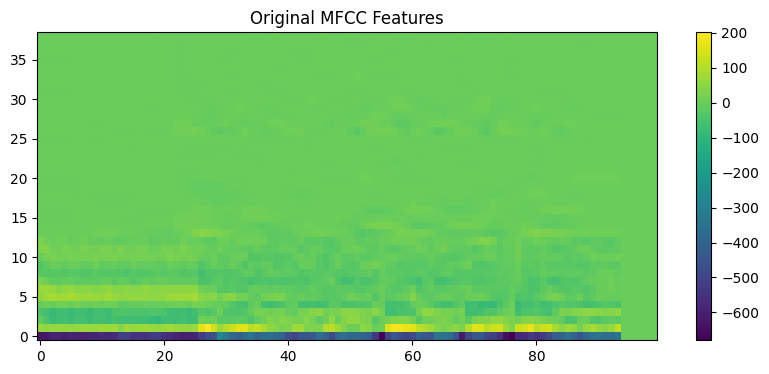

In [ ]:
#Original Feature Image
import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))

plt.imshow(
    sample[0],
    cmap="viridis",
    aspect="auto",
    origin="lower"
)

plt.colorbar()

plt.title("Original MFCC Features")

plt.savefig(
    os.path.join(save_dir,"Original_Input_Features.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

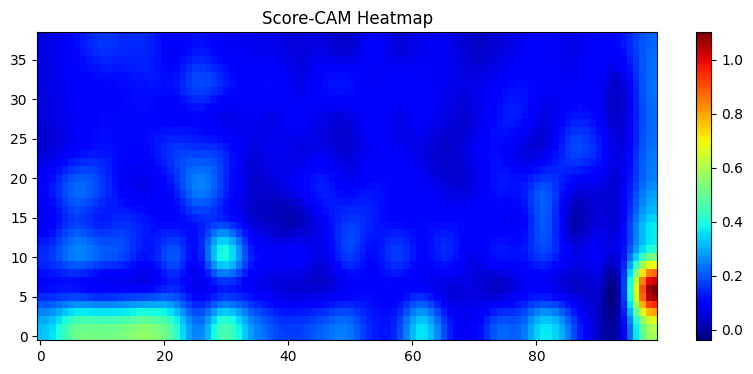

In [ ]:
#Score-CAM Heatmap
plt.figure(figsize=(10,4))

plt.imshow(
    heatmap_resized,
    cmap="jet",
    aspect="auto",
    origin="lower"
)

plt.colorbar()

plt.title("Score-CAM Heatmap")

plt.savefig(
    os.path.join(save_dir,"ScoreCAM_Heatmap.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

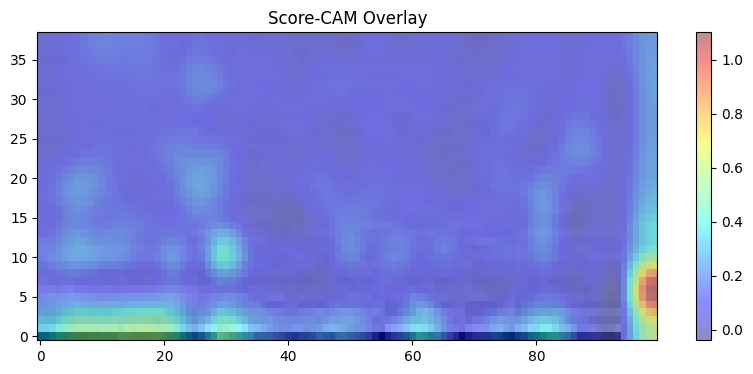

In [ ]:
#Overlay
plt.figure(figsize=(10,4))

plt.imshow(
    sample[0],
    cmap="gray",
    aspect="auto",
    origin="lower"
)

plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.45,
    aspect="auto",
    origin="lower"
)

plt.colorbar()

plt.title("Score-CAM Overlay")

plt.savefig(
    os.path.join(save_dir,"ScoreCAM_Overlay.png"),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
#Heatmap Statistics
import pandas as pd

stats=pd.DataFrame({
    "Statistic":[
        "Minimum",
        "Maximum",
        "Mean",
        "Standard Deviation"
    ],
    "Value":[
        heatmap.min(),
        heatmap.max(),
        heatmap.mean(),
        heatmap.std()
    ]
})

stats.to_csv(
    os.path.join(save_dir,"Heatmap_Statistics.csv"),
    index=False
)

stats

,Statistic,Value
0,Minimum,0.015213
1,Maximum,1.000000
2,Mean,0.129784
3,Standard Deviation,0.107818


In [ ]:
#AI Report
report=pd.DataFrame({

    "Ground Truth":[label_names[true_label]],
    "Prediction":[label_names[predicted_label]],
    "Prediction Probability":[prediction_probability],
    "Heatmap Mean":[heatmap.mean()],
    "Heatmap Maximum":[heatmap.max()],
    "Heatmap Std":[heatmap.std()]

})

report.to_csv(
    os.path.join(save_dir,"AI_Report.csv"),
    index=False
)

report

,Ground Truth,Prediction,Prediction Probability,Heatmap Mean,Heatmap Maximum,Heatmap Std
0,REAL,REAL,0.999798,0.129784,1.0,0.107818


In [ ]:
#Prediction Report
with open(os.path.join(save_dir,"Prediction_Report.txt"),"w") as f:

    f.write("VocaTrust Multilingual Explainable AI Report\n")
    f.write("="*50+"\n\n")

    f.write(f"Ground Truth           : {label_names[true_label]}\n")
    f.write(f"Predicted             : {label_names[predicted_label]}\n")
    f.write(f"Prediction Probability: {prediction_probability:.6f}\n\n")

    f.write("Heatmap Statistics\n")
    f.write("------------------\n")
    f.write(f"Minimum : {heatmap.min():.6f}\n")
    f.write(f"Maximum : {heatmap.max():.6f}\n")
    f.write(f"Mean    : {heatmap.mean():.6f}\n")
    f.write(f"Std Dev : {heatmap.std():.6f}\n")

print("✅ Prediction report saved.")

✅ Prediction report saved.


In [ ]:
#explainable AI v2

In [ ]:
#create folder
import os

base_dir = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Explainable_AI_v2"

folders = [
    "Metadata",
    "Reports",
    "Heatmaps",
    "Arrays",
    "Visualizations"
]

for folder in folders:
    os.makedirs(os.path.join(base_dir, folder), exist_ok=True)

print("✅ Folder structure created successfully.")

✅ Folder structure created successfully.


In [ ]:
#Create multilingual metadata

import numpy as np
import pandas as pd
import os

phase_dir = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual"

# Load labels
y_english = np.load(
    phase_dir + "/English/y_combined.npy"
)

y_hindi = np.load(
    phase_dir + "/Features/Hindi/y_hindi.npy"
)

# Convert labels to text
english_gt = ["REAL" if x == 1 else "FAKE" for x in y_english]
hindi_gt = ["REAL" if x == 1 else "FAKE" for x in y_hindi]

metadata = pd.DataFrame({

    "Sample_ID": np.arange(len(y_english) + len(y_hindi)),

    "Language":
        ["English"] * len(y_english)
        +
        ["Hindi"] * len(y_hindi),

    "GroundTruth":
        english_gt
        +
        hindi_gt

})

metadata_path = (
    phase_dir +
    "/Explainable_AI_v2/Metadata/multilingual_metadata.csv"
)

metadata.to_csv(
    metadata_path,
    index=False
)

print(metadata.head())

print()

print("Total Samples :", len(metadata))

print("English :", sum(metadata.Language=="English"))

print("Hindi :", sum(metadata.Language=="Hindi"))

print("\n✅ multilingual_metadata.csv saved")

KeyboardInterrupt: 

In [ ]:
#Create train_metadata.csv and test_metadata.csv



import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import os

# ==========================================================
# Paths
# ==========================================================

phase_dir = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual"

metadata_dir = os.path.join(
    phase_dir,
    "Explainable_AI_v2",
    "Metadata"
)

# ==========================================================
# Load Metadata
# ==========================================================

metadata = pd.read_csv(
    os.path.join(metadata_dir, "multilingual_metadata.csv")
)

# Load labels used during original split
y_multilingual = np.load(
    os.path.join(
        phase_dir,
        "Combined",
        "y_multilingual.npy"
    )
)

# ==========================================================
# Reproduce EXACT train/test split
# ==========================================================

train_metadata, test_metadata = train_test_split(

    metadata,

    test_size=0.20,

    random_state=42,

    shuffle=True,

    stratify=y_multilingual

)

# Reset indexing
train_metadata = train_metadata.reset_index(drop=True)
test_metadata = test_metadata.reset_index(drop=True)

# Add dataset split column
train_metadata["Dataset"] = "Train"
test_metadata["Dataset"] = "Test"

# ==========================================================
# Save
# ==========================================================

train_metadata.to_csv(
    os.path.join(metadata_dir, "train_metadata.csv"),
    index=False
)

test_metadata.to_csv(
    os.path.join(metadata_dir, "test_metadata.csv"),
    index=False
)

print("Train Samples :", len(train_metadata))
print("Test Samples  :", len(test_metadata))

print("\nTrain Metadata Preview")
print(train_metadata.head())

print("\nTest Metadata Preview")
print(test_metadata.head())

print("\n✅ Metadata files created successfully.")

Train Samples : 90768
Test Samples  : 22692

Train Metadata Preview
   Sample_ID Language GroundTruth Dataset
0      35124  English        FAKE   Train
1      48072  English        REAL   Train
2      10626  English        REAL   Train
3      60846  English        REAL   Train
4      73051  English        FAKE   Train

Test Metadata Preview
   Sample_ID Language GroundTruth Dataset
0     101659    Hindi        REAL    Test
1       8496  English        REAL    Test
2      63920  English        REAL    Test
3      55963  English        REAL    Test
4      44130  English        FAKE    Test

✅ Metadata files created successfully.


In [ ]:
import pandas as pd
import numpy as np
import os

base_dir = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual"

metadata_dir = os.path.join(
    base_dir,
    "Explainable_AI_v2",
    "Metadata"
)

# Load metadata
train_metadata = pd.read_csv(
    os.path.join(metadata_dir, "train_metadata.csv")
)

test_metadata = pd.read_csv(
    os.path.join(metadata_dir, "test_metadata.csv")
)

print("Train Metadata:", train_metadata.shape)
print("Test Metadata :", test_metadata.shape)

test_metadata.head()

Train Metadata: (90768, 4)
Test Metadata : (22692, 4)


,Sample_ID,Language,GroundTruth,Dataset
0,101659,Hindi,REAL,Test
1,8496,English,REAL,Test
2,63920,English,REAL,Test
3,55963,English,REAL,Test
4,44130,English,FAKE,Test


In [ ]:
#Verify Metadata Matches X_test

print("X_test shape :", X_test.shape)
print("Metadata rows:", len(test_metadata))



X_test shape : (22692, 39, 100, 1)
Metadata rows: 22692


In [ ]:
index = 25

sample_info = test_metadata.iloc[index]

print(sample_info)

Sample_ID         8011
Language       English
GroundTruth       REAL
Dataset           Test
Name: 25, dtype: object


In [ ]:
import numpy as np

metadata_labels = np.where(
    test_metadata["GroundTruth"] == "REAL",
    1,
    0
)

print(np.array_equal(metadata_labels, y_test))

True


In [ ]:
print(test_metadata["Language"].value_counts())


Language
English    18353
Hindi       4339
Name: count, dtype: int64


In [ ]:
print(test_metadata.iloc[0])
print(y_test[0])

Sample_ID      101659
Language        Hindi
GroundTruth      REAL
Dataset          Test
Name: 0, dtype: object
1


In [ ]:
#verification

In [ ]:
import pandas as pd
import numpy as np

# Load test metadata
test_metadata = pd.read_csv(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Explainable_AI_v2/Metadata/test_metadata.csv"
)

print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)
print("Metadata rows:", len(test_metadata))

X_test shape : (22692, 39, 100, 1)
y_test shape : (22692,)
Metadata rows: 22692


In [ ]:
metadata_labels = np.where(
    test_metadata["GroundTruth"] == "REAL",
    1,
    0
)

print("Metadata labels shape :", metadata_labels.shape)
print("y_test shape          :", y_test.shape)

print()

print("Labels identical:",
      np.array_equal(metadata_labels, y_test))

Metadata labels shape : (22692,)
y_test shape          : (22692,)

Labels identical: True


In [ ]:
import random

for _ in range(10):

    idx = random.randint(0, len(y_test)-1)

    metadata_gt = test_metadata.iloc[idx]["GroundTruth"]
    y_gt = "REAL" if y_test[idx] == 1 else "FAKE"

    print(f"Index {idx}")
    print("Metadata :", metadata_gt)
    print("y_test   :", y_gt)
    print("-"*40)

Index 7115
Metadata : FAKE
y_test   : FAKE
----------------------------------------
Index 10343
Metadata : FAKE
y_test   : FAKE
----------------------------------------
Index 1510
Metadata : FAKE
y_test   : FAKE
----------------------------------------
Index 14578
Metadata : REAL
y_test   : REAL
----------------------------------------
Index 14063
Metadata : FAKE
y_test   : FAKE
----------------------------------------
Index 16789
Metadata : REAL
y_test   : REAL
----------------------------------------
Index 3948
Metadata : FAKE
y_test   : FAKE
----------------------------------------
Index 12275
Metadata : FAKE
y_test   : FAKE
----------------------------------------
Index 22075
Metadata : REAL
y_test   : REAL
----------------------------------------
Index 3862
Metadata : FAKE
y_test   : FAKE
----------------------------------------


In [ ]:
#testing on the Test dataset

In [ ]:
import pandas as pd

# Load metadata
test_metadata = pd.read_csv(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Explainable_AI_v2/Metadata/test_metadata.csv"
)

# ==========================
# English REAL
# ==========================
english_real = test_metadata[
    (test_metadata["Language"] == "English") &
    (test_metadata["GroundTruth"] == "REAL")
].head(10)

# ==========================
# English FAKE
# ==========================
english_fake = test_metadata[
    (test_metadata["Language"] == "English") &
    (test_metadata["GroundTruth"] == "FAKE")
].head(10)

# ==========================
# Hindi REAL
# ==========================
hindi_real = test_metadata[
    (test_metadata["Language"] == "Hindi") &
    (test_metadata["GroundTruth"] == "REAL")
].head(10)

# ==========================
# Hindi FAKE
# ==========================
hindi_fake = test_metadata[
    (test_metadata["Language"] == "Hindi") &
    (test_metadata["GroundTruth"] == "FAKE")
].head(10)

print("="*70)
print("English + REAL")
print("="*70)
print(english_real)

print("\n")

print("="*70)
print("English + FAKE")
print("="*70)
print(english_fake)

print("\n")

print("="*70)
print("Hindi + REAL")
print("="*70)
print(hindi_real)

print("\n")

print("="*70)
print("Hindi + FAKE")
print("="*70)
print(hindi_fake)

English + REAL
    Sample_ID Language GroundTruth Dataset
1        8496  English        REAL    Test
2       63920  English        REAL    Test
3       55963  English        REAL    Test
5       12629  English        REAL    Test
6       15573  English        REAL    Test
8       10396  English        REAL    Test
9       54216  English        REAL    Test
13      19513  English        REAL    Test
14      16521  English        REAL    Test
21       2190  English        REAL    Test


English + FAKE
    Sample_ID Language GroundTruth Dataset
4       44130  English        FAKE    Test
10      43770  English        FAKE    Test
11      25923  English        FAKE    Test
12      72745  English        FAKE    Test
15      44703  English        FAKE    Test
16      76889  English        FAKE    Test
17      39494  English        FAKE    Test
18      86487  English        FAKE    Test
20      68459  English        FAKE    Test
22      37991  English        FAKE    Test


Hindi + REAL
     Sa

In [ ]:
demo_indices = [1, 4, 0, 19]

for idx in demo_indices:
    print("=" * 50)
    print(f"X_test Index : {idx}")
    print(test_metadata.iloc[idx])

X_test Index : 1
Sample_ID         8496
Language       English
GroundTruth       REAL
Dataset           Test
Name: 1, dtype: object
X_test Index : 4
Sample_ID        44130
Language       English
GroundTruth       FAKE
Dataset           Test
Name: 4, dtype: object
X_test Index : 0
Sample_ID      101659
Language        Hindi
GroundTruth      REAL
Dataset          Test
Name: 0, dtype: object
X_test Index : 19
Sample_ID      110095
Language        Hindi
GroundTruth      FAKE
Dataset          Test
Name: 19, dtype: object


In [ ]:
#testing the TEST DATASET SAMPLE

In [ ]:
from tensorflow.keras.models import load_model

# Load Final Trained Model
model = load_model(
    "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Models/VocaTrust_Multilingual_Final.keras"
)

print("✅ VocaTrust Multilingual Final Model loaded successfully!")

✅ VocaTrust Multilingual Final Model loaded successfully!


In [ ]:
import numpy as np

DEMO_SAMPLES = {
    "English_REAL": 1,
    "English_FAKE": 4,
    "Hindi_REAL": 0,
    "Hindi_FAKE": 19
}

print("="*90)
print("VOICE INTEGRITY MODEL TEST")
print("="*90)

for name, idx in DEMO_SAMPLES.items():

    sample = X_test[idx:idx+1]

    probability = model.predict(sample, verbose=0)[0][0]

    prediction = "REAL" if probability >= 0.5 else "FAKE"

    actual = test_metadata.iloc[idx]["GroundTruth"]
    language = test_metadata.iloc[idx]["Language"]
    sample_id = test_metadata.iloc[idx]["Sample_ID"]

    print("\n" + "="*60)
    print(f"Demo Sample      : {name}")
    print(f"X_test Index     : {idx}")
    print(f"Sample ID        : {sample_id}")
    print(f"Language         : {language}")
    print(f"Ground Truth     : {actual}")
    print(f"Prediction       : {prediction}")
    print(f"REAL Probability : {probability:.6f}")

    if prediction == actual:
        print("Status           : ✅ Correct Prediction")
    else:
        print("Status           : ❌ Wrong Prediction")

VOICE INTEGRITY MODEL TEST

Demo Sample      : English_REAL
X_test Index     : 1
Sample ID        : 8496
Language         : English
Ground Truth     : REAL
Prediction       : REAL
REAL Probability : 1.000000
Status           : ✅ Correct Prediction

Demo Sample      : English_FAKE
X_test Index     : 4
Sample ID        : 44130
Language         : English
Ground Truth     : FAKE
Prediction       : FAKE
REAL Probability : 0.000002
Status           : ✅ Correct Prediction

Demo Sample      : Hindi_REAL
X_test Index     : 0
Sample ID        : 101659
Language         : Hindi
Ground Truth     : REAL
Prediction       : REAL
REAL Probability : 0.999798
Status           : ✅ Correct Prediction

Demo Sample      : Hindi_FAKE
X_test Index     : 19
Sample ID        : 110095
Language         : Hindi
Ground Truth     : FAKE
Prediction       : FAKE
REAL Probability : 0.000000
Status           : ✅ Correct Prediction


In [ ]:
#Folder Paths
# ============================================
# Explainable AI v2 Folder Structure
# ============================================

BASE_DIR = "/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Explainable_AI_v2"

ARRAYS_DIR = os.path.join(BASE_DIR, "Arrays")
HEATMAPS_DIR = os.path.join(BASE_DIR, "Heatmaps")
REPORTS_DIR = os.path.join(BASE_DIR, "Reports")
VISUALS_DIR = os.path.join(BASE_DIR, "Visualizations")
METADATA_DIR = os.path.join(BASE_DIR, "Metadata")

print("✅ Folder paths loaded.")

✅ Folder paths loaded.


In [ ]:
#Load Metadata
# ============================================
# Load Test Metadata
# ============================================

test_metadata = pd.read_csv(
    os.path.join(METADATA_DIR, "test_metadata.csv")
)

print("Total Test Samples :", len(test_metadata))

Total Test Samples : 22692


In [ ]:
# ============================================
# Demo Samples
# ============================================

DEMO_SAMPLES = {

    "English_REAL": 1,
    "English_FAKE": 4,
    "Hindi_REAL": 0,
    "Hindi_FAKE": 19

}

print(DEMO_SAMPLES)

{'English_REAL': 1, 'English_FAKE': 4, 'Hindi_REAL': 0, 'Hindi_FAKE': 19}


In [ ]:
#Select Demo Sample


# ============================================
# Select Demo Sample
# ============================================

sample_name = "English_REAL"

index = DEMO_SAMPLES[sample_name]

sample = X_test[index:index+1]
true_label = y_test[index]

metadata = test_metadata.iloc[index]

sample_id = metadata["Sample_ID"]
language = metadata["Language"]
ground_truth = metadata["GroundTruth"]

print("="*60)
print("Demo Sample :", sample_name)
print("="*60)

print("Sample ID      :", sample_id)
print("Language       :", language)
print("Ground Truth   :", ground_truth)
print("X_test Index   :", index)
print("Sample Shape   :", sample.shape)

Demo Sample : English_REAL
Sample ID      : 8496
Language       : English
Ground Truth   : REAL
X_test Index   : 1
Sample Shape   : (1, 39, 100, 1)


In [ ]:
#Prediction
# ============================================
# Predict the Sample
# ============================================

prediction = model.predict(sample, verbose=0)

prediction_probability = float(prediction[0][0])

predicted_label = 1 if prediction_probability >= 0.5 else 0

label_names = {
    0: "FAKE",
    1: "REAL"
}

prediction_text = label_names[predicted_label]

print("\nPrediction Probability :", prediction_probability)
print("Prediction             :", prediction_text)


Prediction Probability : 1.0
Prediction             : REAL


In [ ]:
# ============================================
# Create Feature Extractor
# ============================================
import tensorflow as tf
feature_extractor = tf.keras.Model(
    inputs=model.inputs,
    outputs=model.get_layer("conv2d_2").output
)

print("✅ Feature Extractor Created")

✅ Feature Extractor Created


In [ ]:
# ============================================
# Generate Feature Maps
# ============================================

feature_maps = feature_extractor.predict(sample, verbose=0)

print("Feature Maps Shape :", feature_maps.shape)

Feature Maps Shape : (1, 9, 25, 128)


In [ ]:
# ============================================
# Create Classifier
# ============================================

classifier = tf.keras.Sequential([

    model.get_layer("batch_normalization_2"),
    model.get_layer("max_pooling2d_2"),
    model.get_layer("dropout_2"),
    model.get_layer("flatten"),
    model.get_layer("dense"),
    model.get_layer("dropout_3"),
    model.get_layer("dense_1")

])

print("✅ Classifier Created")

✅ Classifier Created


In [ ]:
# ============================================
# Verify Classifier
# ============================================

prediction = classifier(
    feature_maps,
    training=False
)

classifier_probability = float(prediction.numpy()[0][0])

classifier_label = 1 if classifier_probability >= 0.5 else 0

print("="*60)
print("Classifier Verification")
print("="*60)

print("Ground Truth :", ground_truth)
print("Prediction   :", label_names[classifier_label])
print("Probability  :", classifier_probability)

Classifier Verification
Ground Truth : REAL
Prediction   : REAL
Probability  : 1.0


In [ ]:
# ============================================
# Save Feature Maps
# ============================================

np.save(

    os.path.join(
        ARRAYS_DIR,
        f"feature_maps_{sample_id}.npy"
    ),

    feature_maps

)

print("✅ Feature Maps Saved")

✅ Feature Maps Saved


In [ ]:
# ============================================
# Resize Heatmap
# ============================================

heatmap_resized = cv2.resize(
    heatmap,
    (100, 39),
    interpolation=cv2.INTER_CUBIC
)

print("Resized Heatmap Shape :", heatmap_resized.shape)

Resized Heatmap Shape : (39, 100)


In [ ]:
# ============================================
# Verification
# ============================================

print("=" * 60)
print("Sample ID        :", sample_id)
print("Language         :", language)
print("Ground Truth     :", ground_truth)
print("Prediction       :", prediction_text)
print("Prediction Score :", prediction_probability)
print()
print("Feature Maps     :", feature_maps.shape)
print("Weights          :", weights.shape)
print("Heatmap          :", heatmap.shape)
print("Resized Heatmap  :", heatmap_resized.shape)
print("=" * 60)

Sample ID        : 8496
Language         : English
Ground Truth     : REAL
Prediction       : REAL
Prediction Score : 1.0

Feature Maps     : (9, 25, 128)
Weights          : (128,)
Heatmap          : (9, 25)
Resized Heatmap  : (39, 100)


Sample ID        : 8496
Language         : English
Ground Truth     : REAL
Prediction       : REAL
Prediction Score : 1.0

Feature Maps     : (9, 25, 128)
Weights          : (128,)
Heatmap          : (9, 25)
Resized Heatmap  : (39, 100)


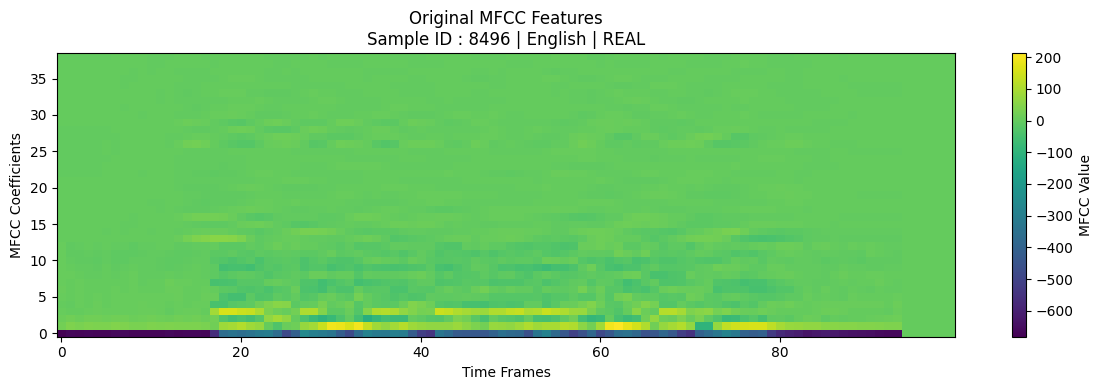

In [ ]:
# ============================================
# Original MFCC Features
# ============================================
import matplotlib.pyplot as plt

plt.figure(figsize=(12,4))

plt.imshow(
    sample[0, :, :, 0],          # Remove channel dimension
    cmap="viridis",
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="MFCC Value")

plt.xlabel("Time Frames")
plt.ylabel("MFCC Coefficients")

plt.title(
    f"Original MFCC Features\n"
    f"Sample ID : {sample_id} | "
    f"{language} | "
    f"{ground_truth}"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        VISUALS_DIR,
        f"Original_Input_{sample_id}.png"
    ),
    dpi=300
)

plt.show()

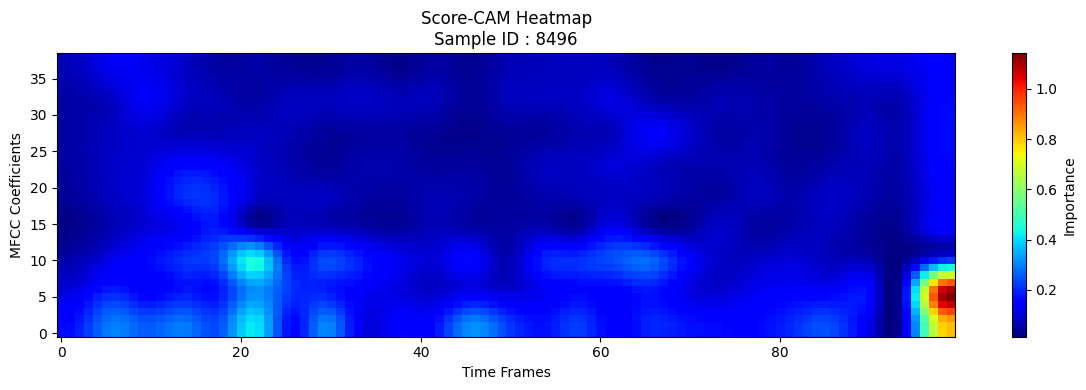

In [ ]:
# ============================================
# Score-CAM Heatmap
# ============================================

plt.figure(figsize=(12,4))

plt.imshow(
    heatmap_resized,
    cmap="jet",
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="Importance")

plt.xlabel("Time Frames")
plt.ylabel("MFCC Coefficients")

plt.title(
    f"Score-CAM Heatmap\n"
    f"Sample ID : {sample_id}"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        VISUALS_DIR,
        f"ScoreCAM_Heatmap_{sample_id}.png"
    ),
    dpi=300
)

plt.show()

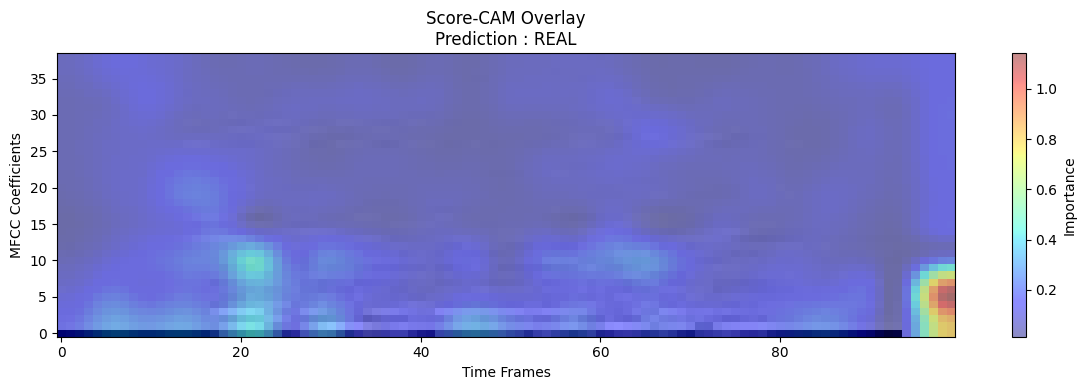

In [ ]:
# ============================================
# Score-CAM Overlay
# ============================================

plt.figure(figsize=(12,4))

# Original MFCC
plt.imshow(
    sample[0, :, :, 0],
    cmap="gray",
    aspect="auto",
    origin="lower"
)

# Overlay
plt.imshow(
    heatmap_resized,
    cmap="jet",
    alpha=0.45,
    aspect="auto",
    origin="lower"
)

plt.colorbar(label="Importance")

plt.xlabel("Time Frames")
plt.ylabel("MFCC Coefficients")

plt.title(
    f"Score-CAM Overlay\n"
    f"Prediction : {prediction_text}"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        HEATMAPS_DIR,
        f"ScoreCAM_Overlay_{sample_id}.png"
    ),
    dpi=300
)

plt.show()

In [ ]:
print("Saved Files")

print()

print(os.path.join(
    VISUALS_DIR,
    f"Original_Input_{sample_id}.png"
))

print(os.path.join(
    VISUALS_DIR,
    f"ScoreCAM_Heatmap_{sample_id}.png"
))

print(os.path.join(
    HEATMAPS_DIR,
    f"ScoreCAM_Overlay_{sample_id}.png"
))

Saved Files

/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Explainable_AI_v2/Visualizations/Original_Input_8496.png
/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Explainable_AI_v2/Visualizations/ScoreCAM_Heatmap_8496.png
/content/drive/MyDrive/VocaTrust/Phase6_Multilingual/Explainable_AI_v2/Heatmaps/ScoreCAM_Overlay_8496.png


In [ ]:

# ============================================
# Heatmap Statistics
# ============================================

stats = pd.DataFrame({

    "Statistic": [
        "Minimum",
        "Maximum",
        "Mean",
        "Standard Deviation"
    ],

    "Value": [
        float(heatmap.min()),
        float(heatmap.max()),
        float(heatmap.mean()),
        float(heatmap.std())
    ]

})

stats.to_csv(
    os.path.join(
        REPORTS_DIR,
        f"Heatmap_Statistics_{sample_id}.csv"
    ),
    index=False
)

print("✅ Heatmap Statistics Saved")

stats

✅ Heatmap Statistics Saved


,Statistic,Value
0,Minimum,0.021437
1,Maximum,1.000000
2,Mean,0.111041
3,Standard Deviation,0.100069


In [ ]:
# ============================================
# Confidence and Risk Analysis
# ============================================

if predicted_label == 1:
    confidence = prediction_probability * 100
else:
    confidence = (1 - prediction_probability) * 100

voice_integrity_score = confidence

if voice_integrity_score >= 80:
    risk_level = "Genuine"

elif voice_integrity_score >= 50:
    risk_level = "Suspicious"

else:
    risk_level = "Fake"

print("Confidence           :", round(confidence,2), "%")
print("Voice Integrity Score:", round(voice_integrity_score,2))
print("Risk Level           :", risk_level)

Confidence           : 100.0 %
Voice Integrity Score: 100.0
Risk Level           : Genuine


In [ ]:
# ============================================
# Professional AI Report
# ============================================

report = pd.DataFrame({

    "Sample ID": [sample_id],
    "Language": [language],

    "Ground Truth": [ground_truth],
    "Prediction": [prediction_text],

    "Prediction Probability": [round(prediction_probability,6)],
    "Confidence (%)": [round(confidence,2)],

    "Voice Integrity Score": [round(voice_integrity_score,2)],
    "Risk Level": [risk_level],

    "Heatmap Mean": [round(float(heatmap.mean()),6)],
    "Heatmap Maximum": [round(float(heatmap.max()),6)],
    "Heatmap Std": [round(float(heatmap.std()),6)]

})

report.to_csv(

    os.path.join(
        REPORTS_DIR,
        f"AI_Report_{sample_id}.csv"
    ),

    index=False

)

print("✅ AI Report Saved")

report

✅ AI Report Saved


,Sample ID,Language,Ground Truth,Prediction,Prediction Probability,Confidence (%),Voice Integrity Score,Risk Level,Heatmap Mean,Heatmap Maximum,Heatmap Std
0,8496,English,REAL,REAL,1.0,100.0,100.0,Genuine,0.111041,1.0,0.100069


In [ ]:
# ============================================
# Voice Integrity Analysis Report
# ============================================

print("="*70)
print("           VOICATRUST AI ANALYSIS REPORT")
print("="*70)

print(f"Sample ID             : {sample_id}")
print(f"Language              : {language}")
print(f"Ground Truth          : {ground_truth}")

print()

print(f"Prediction            : {prediction_text}")
print(f"Confidence            : {confidence:.2f}%")
print(f"Voice Integrity Score : {voice_integrity_score:.2f}/100")
print(f"Risk Level            : {risk_level}")

print()

print("Heatmap Statistics")
print("------------------------------")
print(f"Maximum Importance    : {heatmap.max():.6f}")
print(f"Average Importance    : {heatmap.mean():.6f}")
print(f"Standard Deviation    : {heatmap.std():.6f}")

print()

print("Interpretation")
print("------------------------------")

if prediction_text == "REAL":
    print("The model classified this voice as GENUINE.")
    print("Score-CAM highlights the MFCC regions that")
    print("most strongly contributed to the REAL prediction.")
else:
    print("The model classified this voice as FAKE.")
    print("Score-CAM highlights the MFCC regions that")
    print("most strongly contributed to the FAKE prediction.")

print("="*70)

           VOICATRUST AI ANALYSIS REPORT
Sample ID             : 8496
Language              : English
Ground Truth          : REAL

Prediction            : REAL
Confidence            : 100.00%
Voice Integrity Score : 100.00/100
Risk Level            : Genuine

Heatmap Statistics
------------------------------
Maximum Importance    : 1.000000
Average Importance    : 0.111041
Standard Deviation    : 0.100069

Interpretation
------------------------------
The model classified this voice as GENUINE.
Score-CAM highlights the MFCC regions that
most strongly contributed to the REAL prediction.
